# Figur 5 · Holdt partierne, hvad de sagde, emne for emne?

**Underspørgsmål 3, pr. emne.** For hvert parti og emne sammenligner vi:

- **SAGDE:** partiets gennemsnitlige stance i DR/TV 2-citater om emnet, håndkodet af to fra gruppen (−1 = imod, +1 = for).
- **GJORDE:** andelen af partiets stemmer på nøglelovene, der gik i stancens retning. For "bred regering": andelen af omstridte afstemninger, hvor partiet stemte med regeringen.

**Før du starter**, læg disse filer i `data/`:
- `noeglelove.csv` med retningen gennemgået. Mangler den, bruger notebooken en indbygget liste med de samme 11 love.
- `emnecitater_kodeark.csv`, udfyldt af to af jer hver for sig. Indtil den er klar, bruger notebooken `lda_stance_results.csv`, som I allerede har.

Notebooken ligger i `notebooks/`, så data findes i `../data/`.

## 1 · Opsætning

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

MAPPE = "../data/"
PARTIER = ["S", "V", "M", "SF", "DD", "LA", "KF", "EL", "DF", "RV", "ALT"]
REGERING = {"S", "V", "M"}
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2",
          "LA": "#3FB2BE", "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738"}
EMNER = ["Skattelettelser", "CO2-afgift / grøn omstilling", "Bred regering"]
MIN_CITATER = 3          # mindst 3 citater pr. parti og emne

## 2 · SAGDE: hvad partierne sagde i citaterne

Notebooken bruger én af to kilder og vælger selv:

- **A · Håndkodet (anbefalet):** `emnecitater_kodeark.csv` i `data/`, udfyldt af to af jer. Bruges automatisk, når filen findes og er kodet.
- **B · Stance-modellen (midlertidig):** `lda_stance_results.csv`. Bruges, indtil A er klar. Modellen er ikke valideret og gav fx LA og KF negativ stance på skattelettelser, selvom begge havde "lavere skat" som mærkesag. **Brug ikke B i den endelige figur.**

I B bruges samme relevansfilter som jeres `milestone8a`: kun citater, der faktisk nævner emnet.

In [20]:
from pathlib import Path

VAERDI = {"for": 1, "neutral": 0, "imod": -1}
kodeark = Path(MAPPE + "emnecitater_kodeark.csv")
kappa = None

if kodeark.exists():
    ark = pd.read_csv(kodeark, sep=";", encoding="utf-8-sig")
    ark.columns = ["id", "emne", "spoergsmaal", "parti", "politiker", "dato", "kilde", "citat",
                   "relevant", "k1", "k2", "note"]                   # korte kolonnenavne
    for c in ["relevant", "k1", "k2"]:
        ark[c] = ark[c].astype(str).str.strip().str.lower()
    ark = ark[(ark["relevant"] != "nej") & ark["k1"].isin(VAERDI) & ark["k2"].isin(VAERDI)]

if kodeark.exists() and len(ark):
    KILDE = "håndkodet"
    kappa = cohen_kappa_score(ark["k1"], ark["k2"])
    print(f"A · Håndkodet: {len(ark)} citater, kodere enige om {(ark['k1'] == ark['k2']).mean():.0%}, κ = {kappa:.2f}")
    enige = ark[ark["k1"] == ark["k2"]].copy()
    enige["v"] = enige["k1"].map(VAERDI)
    enige["stance"] = enige["k1"]
    citater = enige[["emne", "parti", "politiker", "dato", "kilde", "stance", "v", "citat"]]
else:
    KILDE = "stance-model"
    print("B · Kodearket findes ikke eller er ikke udfyldt. Bruger lda_stance_results.csv.")
    LDA = {"Skattelettelser": ("Blokpolitik & Statsfinanser",
                               r"skat|topskat|økonomi|milliard|inflation|finans|budget|blå blok|rød blok|borgerlig"),
           "CO2-afgift / grøn omstilling": ("Økonomi & Landbrug",
                               r"co2|landbrug|klima|grøn|afgift|landmænd|natur|miljø"),
           "Bred regering": ("Regeringsdannelse & Midten",
                               r"regering|midten|samarbejd|bred|statsminister|blok|flertal|moderaterne|dronningerunde|mandat")}
    q = pd.read_csv("/Users/sabirinomar/Politics-Network/data/lda_stance_results.csv", encoding="utf-8-sig")
    q = q[q["parti"].isin(PARTIER)]
    dele = []
    for emne, (lda_emne, regex) in LDA.items():
        d = q[(q["lda_emne"] == lda_emne) & q["citat"].str.lower().str.contains(regex)].copy()
        d["emne"] = emne
        dele.append(d)
    citater = pd.concat(dele)
    citater["v"] = citater["stance_label"].map({"For": 1, "Neutral": 0, "Imod": -1})
    citater["stance"] = citater["stance_label"].str.lower()
    citater = citater.rename(columns={"politiker": "politiker"})[["emne", "parti", "politiker", "stance", "v", "citat"]]
    print(len(citater), "relevante citater fra stance-modellen")

sagde = citater.groupby(["emne", "parti"])["v"].agg(stance="mean", n="size").reset_index()
print("\nCitater pr. parti og emne (før tærsklen):")
print(sagde.pivot(index="emne", columns="parti", values="n").reindex(columns=PARTIER).fillna(0).astype(int))
sagde = sagde[sagde["n"] >= MIN_CITATER]
sagde.round(2)

B · Kodearket findes ikke eller er ikke udfyldt. Bruger lda_stance_results.csv.
115 relevante citater fra stance-modellen

Citater pr. parti og emne (før tærsklen):
parti                          S  V  M  SF  DD  LA  KF  EL  DF  RV  ALT
emne                                                                   
Bred regering                 40  0  8   3   6   3   2   5   0   4    0
CO2-afgift / grøn omstilling   0  3  3   9   0   0   0   3   0   0    0
Skattelettelser                5  0  2   2   1   7   4   3   2   0    0


,emne,parti,stance,n
0,Bred regering,DD,-0.50,6
1,Bred regering,EL,-0.80,5
3,Bred regering,LA,-0.33,3
4,Bred regering,M,-0.12,8
5,Bred regering,RV,0.75,4
6,Bred regering,S,0.28,40
7,Bred regering,SF,-0.33,3
8,CO2-afgift / grøn omstilling,EL,0.33,3
9,CO2-afgift / grøn omstilling,M,-0.67,3
10,CO2-afgift / grøn omstilling,SF,0.11,9


## 3 · Partiernes position på hver afstemning

Partiets stemme er flertallet blandt de medlemmer, der stemte for eller imod.

In [21]:
st = pd.read_csv("/Users/sabirinomar/Politics-Network/data/processed/stemmer_2022_2026.csv",
                 usecols=["afstemning_id", "afstemningstype", "parti", "stemme"])
st = st[st["parti"].isin(PARTIER) & st["stemme"].isin(["For", "Imod"])]

position = (st.groupby(["afstemning_id", "parti"])["stemme"]
              .agg(lambda x: x.value_counts().idxmax()).unstack())
print(len(position), "afstemninger")

1514 afstemninger


## 4 · GJORDE: stemmer i stancens retning

**Nøglelove:** `retning` i `noeglelove.csv` er +1, hvis en for-stemme er for stancen, og −1, hvis den er imod (fx L 64 B, der suspenderer en CO2-afgift). Partiets stemme (+1 for, −1 imod) ganget med retningen giver +1, når partiet stemte i stancens retning.

**Bred regering:** kun **omstridte** endelige vedtagelser, hvor mindst tre oppositionspartier stemte imod regeringen. De fleste love vedtages med bredt flertal, og at stemme for dem er ikke det samme som at støtte en bred regering.

In [25]:
# Indlæs afstemninger og filtrer til endelige vedtagelser af lovforslag
afst_alle = pd.read_csv("/Users/sabirinomar/Politics-Network/data/processed/afstemninger_2022_2026.csv")
endelige_love = afst_alle[
    (afst_alle["afstemningstype"] == "Endelig vedtagelse") & 
    (afst_alle["sagstype"] == "Lovforslag")
].copy()

tekst = (endelige_love["titel_kort"].fillna("") + " " + endelige_love["resume"].fillna("")).str.lower()

# 1. Find skattelettelser (under økonomi/skat og med ord om skattenedsættelse/afskaffelse af afgift)
er_skat = (
    endelige_love["emne"].isin(["Økonomi, skat & energipriser", "Sundhed & psykiatri"]) &
    tekst.str.contains(r"personskat|bundskat|topskat|seniorpræmie|afskaffelse af .*afgift|skattelettelse")
)

# 2. Find CO2-afgift / grøn omstilling (under klima eller økonomi/energipriser)
er_co2 = (
    endelige_love["emne"].isin(["Klima, miljø & landbrug", "Økonomi, skat & energipriser"]) &
    tekst.str.contains(r"co2|drivhusgas|grøn skattereform|energiafgiften på fossile")
)

# Saml til én tabel med samme struktur som før
skat_df = endelige_love[er_skat].assign(emne="Skattelettelser", retning=1)
co2_df = endelige_love[er_co2].assign(emne="CO2-afgift / grøn omstilling", retning=1)

# Sæt retning = -1 hvis loven suspenderer eller udskyder en afgift (fx L 64 B)
co2_df.loc[co2_df["titel_kort"].str.lower().str.contains(r"suspension|udskydelse"), "retning"] = -1

love = pd.concat([skat_df, co2_df], ignore_index=True)[
    ["afstemning_id", "sag_nummer", "emne", "retning", "titel_kort"]
].rename(columns={"sag_nummer": "sag", "titel_kort": "titel"})

print(f"Fandt {len(love)} nøglelove direkte i afstemninger_2022_2026.csv:")
print(love.groupby("emne").size().to_string())
display(love)

Fandt 38 nøglelove direkte i afstemninger_2022_2026.csv:
emne
CO2-afgift / grøn omstilling    29
Skattelettelser                  9


,afstemning_id,sag,emne,retning,titel
0,9187,L 76 B,Skattelettelser,1,Om nedsættelse af bundskatten som følge af kommunale skattestigninger.
1,9211,L 114,Skattelettelser,1,Om opfølgning på forlig om tryghed om boligbeskatningen og aftalen om kompensation til boligejerne og fortsat tryghed om boligbeskatningen.
2,9554,L 93 B,Skattelettelser,1,Om nedsættelse af bundskatten som følge af kommunale skattestigninger.
3,9607,L 119 C,Skattelettelser,1,"Om ændring af chokoladeafgiftsloven, kildeskatteloven og forskellige andre love."
4,9656,L 138,Skattelettelser,1,Om udmøntning af dele af aftale om reform af personskat.
5,9817,L 132,Skattelettelser,1,Om udgiftslofter og konsekvenser af aftale om reform af personskat m.v.
6,10419,L 28,Skattelettelser,1,Om forhøjelse af den skattefri seniorpræmie m.v.
7,10572,L 1,Skattelettelser,1,Om ophævelse af chokoladeafgiftsloven m.v.
8,10613,L 36 A,Skattelettelser,1,Om afskaffelse af kaffeafgiften og indførelse af motions- og musikundervisningsfradrag m.v.
9,9011,L 6,CO2-afgift / grøn omstilling,1,Om deltagelse i CO2-lagringsaktiviteter.


## 5 · Kobl SAGDE og GJORDE

En stance over +0,15 tæller som *for*, under −0,15 som *imod*; ellers er partiet neutralt. En stemmeandel på mindst 0,6 tæller som *stemte for*, højst 0,4 som *stemte imod*.

In [26]:
gj = [gjorde_regering(p) if e == "Bred regering" else gjorde_lov(e, p)
      for e, p in zip(sagde["emne"], sagde["parti"])]
sagde["gjorde"] = [g[0] for g in gj]
sagde["n_stemmer"] = [g[1] for g in gj]
res = sagde.dropna(subset=["gjorde"]).copy()

res["dom"] = np.select(
    [(res["stance"] > 0.15) & (res["gjorde"] >= 0.6), (res["stance"] < -0.15) & (res["gjorde"] <= 0.4),
     (res["stance"] > 0.15) & (res["gjorde"] <= 0.4), (res["stance"] < -0.15) & (res["gjorde"] >= 0.6)],
    ["alignment", "alignment", "divergens", "divergens"], default="uklart")

print(res["dom"].value_counts().to_string())
res.round(2)

dom
uklart       6
alignment    5
divergens    4


,emne,parti,stance,n,gjorde,n_stemmer,dom
0,Bred regering,DD,-0.50,6,0.45,230,uklart
1,Bred regering,EL,-0.80,5,0.29,233,alignment
3,Bred regering,LA,-0.33,3,0.49,156,uklart
4,Bred regering,M,-0.12,8,1.00,230,uklart
5,Bred regering,RV,0.75,4,0.44,227,uklart
6,Bred regering,S,0.28,40,1.00,238,alignment
7,Bred regering,SF,-0.33,3,0.38,220,alignment
8,CO2-afgift / grøn omstilling,EL,0.33,3,0.92,24,alignment
9,CO2-afgift / grøn omstilling,M,-0.67,3,1.00,25,divergens
10,CO2-afgift / grøn omstilling,SF,0.11,9,1.00,23,uklart


## 6 · Tegn figur 5

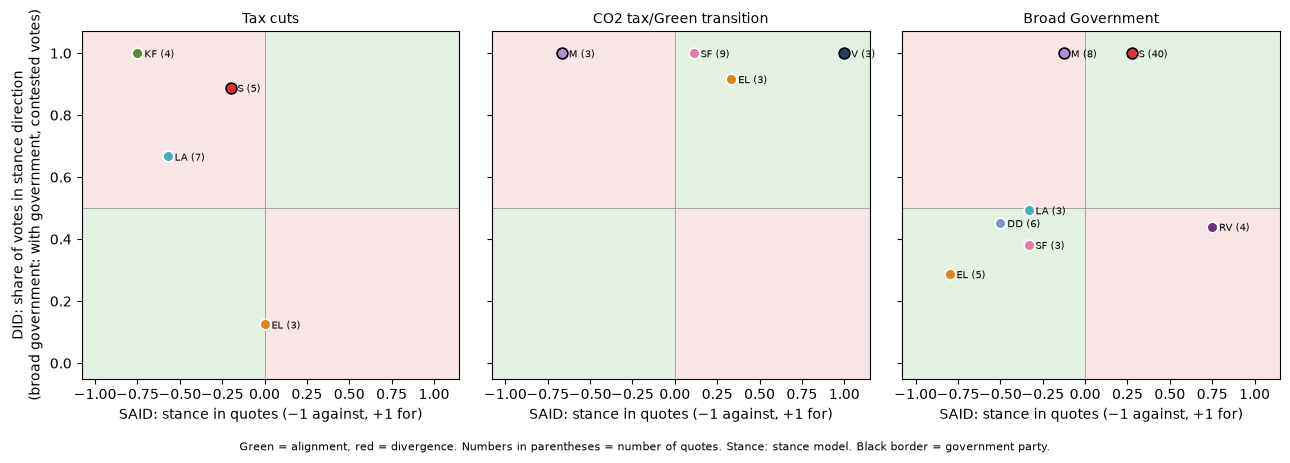

In [41]:
EMNE_EN = {
    "Skattelettelser": "Tax cuts",
    "CO2-afgift / grøn omstilling": "CO2 tax/Green transition",
    "Bred regering": "Broad Government"
}

KILDE_EN = {
    "håndkodet": "hand-coded",
    "stance-model": "stance model",
    "stance-model (ikke valideret)": "stance model (unvalidated)"
}.get(KILDE, KILDE)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, emne in zip(axes, EMNER):
    # green areas = alignment, red = divergence
    for x0, y0, w, h, farve in [
        (0, 0.5, 1.15, 0.57, "#e3f1e3"),
        (-1.08, -0.05, 1.08, 0.55, "#e3f1e3"),
        (-1.08, 0.5, 1.08, 0.57, "#f8e6e6"),
        (0, -0.05, 1.15, 0.55, "#f8e6e6")
    ]:
        ax.add_patch(plt.Rectangle((x0, y0), w, h, color=farve, zorder=0))

    ax.axhline(0.5, color="#999", lw=0.6)   # <-- rettet tilbage fra 1 til 0.5
    ax.axvline(0, color="#999", lw=0.6)

    for _, r in res[res["emne"] == emne].iterrows():
        ax.scatter(r["stance"], r["gjorde"], s=60, color=FARVER[r["parti"]],
                   edgecolor="k" if r["parti"] in REGERING else "white", lw=1.2, zorder=3)
        ax.annotate(f"{r['parti']} ({r['n']})", (r["stance"], r["gjorde"]),
                    xytext=(5, -3), textcoords="offset points", fontsize=7)

    ax.set_xlim(-1.08, 1.15)
    ax.set_ylim(-0.05, 1.07)
    ax.set_title(EMNE_EN.get(emne, emne), fontsize=10)
    ax.set_xlabel("SAID: stance in quotes (−1 against, +1 for)")

axes[0].set_ylabel("DID: share of votes in stance direction\n(broad government: with government, contested votes)")
kilde_tekst = f"Stance: {KILDE_EN}" + (f", κ = {kappa:.2f}" if kappa is not None else "")
fig.text(0.5, -0.03, f"Green = alignment, red = divergence. Numbers in parentheses = number of quotes. "
                     f"{kilde_tekst}. Black border = government party.", ha="center", fontsize=8)

plt.tight_layout()
fig.savefig("fig5_pr_emne.pdf", bbox_inches="tight")
fig.savefig("fig5_pr_emne.png", dpi=300, bbox_inches="tight")
plt.show()

## 6b · Citaterne bag figuren

Præcis de citater, der indgår i figuren: kun partier og emner med mindst `MIN_CITATER` citater. Gemmes som `citater_i_figur5.csv`, så I kan læse dem og citere eksempler i paperet.

In [31]:
brugt = citater.merge(res[["emne", "parti"]], on=["emne", "parti"])      # kun dem, der er punkter i figuren
brugt = brugt.sort_values(["emne", "parti", "v"]).reset_index(drop=True)
brugt.drop(columns="v").to_csv("citater_i_figur5.csv", index=False, sep=";", encoding="utf-8-sig")
print(len(brugt), "citater bag", len(res), "punkter i figuren")

pd.set_option("display.max_colwidth", 200)
for (emne, parti), d in brugt.groupby(["emne", "parti"]):
    r = res[(res["emne"] == emne) & (res["parti"] == parti)].iloc[0]
    print(f"\n=== {emne} · {parti}: stance {r['stance']:+.2f}, stemte i retningen {r['gjorde']:.0%} → {r['dom']}")
    for _, c in d.iterrows():
        print(f"  [{c['stance']:>7}] {c['citat'][:220]}")

106 citater bag 15 punkter i figuren

=== Bred regering · DD: stance -0.50, stemte i retningen 45% → uklart
  [   imod] Ja, altså vi ser i hvert fald ikke, at man skal fjerne topskatten, sagde Inger Støjberg og nævnte, at den tidligere Thorning-regering hævede beløbsgrænsen for, hvornår man skal betale topskat.
  [   imod] Arh, jeg har godt nok svært ved at se mig selv i en regering, hvor Barbara Bertelsen sidder for bordenden, som hun gør nu, svarede Inger Støjberg.
  [   imod] Jeg vil i hvert fald sige, at jeg har meget, meget svært ved at se Barbara Bertelsen spille en særlig stor rolle, hvis der kommer en borgerlig regering.
  [   imod] Min bekymring er, at udlændingepolitikken kan ende med at blive lempet, hvis der, som nogle partier taler for, skal dannes en regering hen over midten.
  [neutral] Hun står ved, hvad hun siger Som statsministeren har også Inger Støjberg anskaffet sig en valgbus.
  [    for] Nej, fordi forsvarsforligskredsen er ikke sammensat endnu. Alle er enige i r

In [32]:
tabel = brugt[["emne", "parti", "politiker", "stance", "citat"]]
tabel.to_csv("citater_i_figur5.csv", index=False, sep=";", encoding="utf-8-sig")
tabel

,emne,parti,politiker,stance,citat
0,Bred regering,DD,Inger Støjberg,imod,"Ja, altså vi ser i hvert fald ikke, at man skal fjerne topskatten, sagde Inger Støjberg og nævnte, at den tidligere Thorning-regering hævede beløbsgrænsen for, hvornår man skal betale topskat."
1,Bred regering,DD,Inger Støjberg,imod,"Arh, jeg har godt nok svært ved at se mig selv i en regering, hvor Barbara Bertelsen sidder for bordenden, som hun gør nu, svarede Inger Støjberg."
2,Bred regering,DD,Inger Støjberg,imod,"Jeg vil i hvert fald sige, at jeg har meget, meget svært ved at se Barbara Bertelsen spille en særlig stor rolle, hvis der kommer en borgerlig regering."
3,Bred regering,DD,Inger Støjberg,imod,"Min bekymring er, at udlændingepolitikken kan ende med at blive lempet, hvis der, som nogle partier taler for, skal dannes en regering hen over midten."
4,Bred regering,DD,Inger Støjberg,neutral,"Hun står ved, hvad hun siger Som statsministeren har også Inger Støjberg anskaffet sig en valgbus."
...,...,...,...,...,...
101,Skattelettelser,S,Astrid Krag,imod,"Det er fuldstændig afgørende, at vi ikke laver en økonomisk politik, der puster til inflationen, for det vil også ramme dem, som har det hårdest. Derfor har vi haft fokus på, hvor vi kan lave en m..."
102,Skattelettelser,S,Mette Frederiksen,imod,"Mette Frederiksen, kameraet er der, værsgo at sige undskyld til de minkavlere, der har mistet hele deres erhverv og hele deres liv... Og til skatteyderne, der har tabt 19 milliarder kroner."
103,Skattelettelser,S,Mette Frederiksen,imod,"Mette Frederiksen er udfordret af, at hun skal levere et dobbelt budskab. Hendes opgave er at styrke Socialdemokratiet og rød blok, fordi det vil give hende muligheden for at blive statsminister i..."
104,Skattelettelser,S,Mette Frederiksen,for,"Ja, det afgørende for os er, at vi får en sammenhængende politik, som ikke kommer til at øge de økonomiske skel i samfundet. Konkret hvordan en skattereform skal udformes, det må vi jo se på."


In [33]:
# 1. Indlæs metadata om afstemninger
afst = pd.read_csv("/Users/sabirinomar/Politics-Network/data/processed/afstemninger_2022_2026.csv",
                   usecols=["afstemning_id", "sag_nummer", "titel_kort", "dato", "resume"]).set_index("afstemning_id")

def kort(tekst, max_tegn=70):
    tekst = str(tekst).strip().rstrip(".")
    return tekst if len(tekst) <= max_tegn else tekst[:max_tegn].rsplit(" ", 1)[0] + " …"

# 2. Byg og gem lang tabel (én række pr. emne, parti og lov)
rækker_lang = []
for _, r in res[res["emne"] != "Bred regering"].iterrows():
    emne_love = love[love["emne"] == r["emne"]]
    for _, lov in emne_love.iterrows():
        aid = lov["afstemning_id"]
        if aid not in position.index or pd.isna(position.at[aid, r["parti"]]):
            continue
            
        stemme = position.at[aid, r["parti"]]
        i_retning = (1 if stemme == "For" else -1) * lov["retning"] == 1
        
        rækker_lang.append({
            "emne": r["emne"],
            "parti": r["parti"],
            "lov": afst.at[aid, "sag_nummer"],
            "titel": kort(afst.at[aid, "titel_kort"]),
            "dato": afst.at[aid, "dato"],
            "resume": kort(afst.at[aid, "resume"], 120),
            "stemte": stemme,
            "i_stancens_retning": "ja" if i_retning else "nej"
        })

lang = pd.DataFrame(rækker_lang)
lang.to_csv("stemmer_paa_noeglelove.csv", index=False, sep=";", encoding="utf-8-sig")

# 3. Hjælpefunktioner til hovedtabellen
def find_citat(emne, parti):
    d = brugt[(brugt["emne"] == emne) & (brugt["parti"] == parti)]
    flertal = d["stance"].mode().iloc[0]
    citater = d[d["stance"] == flertal]["citat"]
    sorteret = citater.loc[citater.str.len().sort_values().index]
    mellem_citat = sorteret.iloc[len(sorteret) // 2]
    return f"({flertal}) «{kort(mellem_citat, 160)}»"

def find_resume(emne, parti):
    if emne == "Bred regering":
        har_stemt = pe[parti].notna()
        afvigelser = pe.index[har_stemt & (pe[parti] != reg)]
        resumer = [f"{afst.at[a, 'sag_nummer']}: {kort(afst.at[a, 'resume'], 100)}"
                   for a in afvigelser[:2] if a in afst.index]
        return "; ".join(resumer) if resumer else "Fulgte regeringen i alle omstridte afstemninger"
    
    d = lang[(lang["emne"] == emne) & (lang["parti"] == parti)]
    return "; ".join(f"{r['lov']}: {r['resume']}" for _, r in d.iterrows())

def find_stemmetekst(emne, parti):
    if emne == "Bred regering":
        har_stemt = pe[parti].notna()
        antal_med = int((pe.loc[har_stemt, parti] == reg[har_stemt]).sum())
        afvigelser = pe.index[har_stemt & (pe[parti] != reg)]
        
        eksempler = []
        for a in afvigelser[:2]:
            if a in afst.index:
                eksempler.append(f"{afst.at[a, 'sag_nummer']} {kort(afst.at[a, 'titel_kort'], 45)} ({parti}: {pe.at[a, parti]}, regeringen: {reg[a]})")
        
        tekst = f"Stemte som regeringen i {antal_med} af {int(har_stemt.sum())} omstridte afstemninger"
        return tekst + (f". Anderledes end regeringen fx: {'; '.join(eksempler)}" if eksempler else "")
    
    d = lang[(lang["emne"] == emne) & (lang["parti"] == parti)]
    return "; ".join(f"{r['lov']} {kort(r['titel'], 40)}: {r['stemte']}" for _, r in d.iterrows())

# 4. Byg og gem hovedtabellen
rækker_under = []
for _, r in res.sort_values(["emne", "parti"]).iterrows():
    rækker_under.append({
        "Emne": r["emne"],
        "Parti": r["parti"],
        "Sagde (eksempel)": find_citat(r["emne"], r["parti"]),
        "Gns. stance": f"{r['stance']:+.2f}",
        "Resume": find_resume(r["emne"], r["parti"]),
        "Stemte": find_stemmetekst(r["emne"], r["parti"]),
        "Andel i stancens retning": f"{r['gjorde']:.0%}",
        "Dom": r["dom"]
    })

under_figur = pd.DataFrame(rækker_under)
under_figur.to_csv("tabel_sagde_vs_stemte.csv", index=False, sep=";", encoding="utf-8-sig")

# 5. Vis tabellen uden farver
(under_figur.style
    .hide(axis="index")
    .set_properties(subset=["Sagde (eksempel)", "Resume", "Stemte"], **{"white-space": "normal", "text-align": "left", "min-width": "320px"}))



Emne,Parti,Sagde (eksempel),Gns. stance,Resume,Stemte,Andel i stancens retning,Dom
Bred regering,DD,"(imod) «Jeg vil i hvert fald sige, at jeg har meget, meget svært ved at se Barbara Bertelsen spille en særlig stor rolle, hvis der kommer en borgerlig regering»",-0.50,"L 4 B: Den daværende regering (Socialdemokratiet), Dansk Folkeparti, Socialistisk Folkeparti og …; L 13: Forslaget afskaffer store bededag (fjerde fredag efter påske) som helligdag og fastsætter store …","Stemte som regeringen i 104 af 230 omstridte afstemninger. Anderledes end regeringen fx: L 4 B Om fastholdelse af loft over … (DD: Imod, regeringen: For); L 13 Om konsekvenser ved afskaffelsen af store … (DD: Imod, regeringen: For)",45%,uklart
Bred regering,EL,"(imod) «Det er klart, hvis Enhedslisten skal støtte en ny regering, så kommer det også med betingelser, og det bliver blandt andet i forhold til, at man ikke kan føre …»",-0.80,"L 1: Med lovforslaget ønskes det, at man forlænger muligheden for udbetaling af det midlertidige …; L 13: Forslaget afskaffer store bededag (fjerde fredag efter påske) som helligdag og fastsætter store …","Stemte som regeringen i 67 af 233 omstridte afstemninger. Anderledes end regeringen fx: L 1 Om forlængelse af det midlertidige … (EL: For, regeringen: Imod); L 13 Om konsekvenser ved afskaffelsen af store … (EL: Imod, regeringen: For)",29%,alignment
Bred regering,LA,"(imod) «Ja, altså så længe Lars Løkke insisterer på, at han ikke vil have en borgerlig regering – ikke engang hvis han selv er statsminister – men at han derimod vil …»",-0.33,"L 13: Forslaget afskaffer store bededag (fjerde fredag efter påske) som helligdag og fastsætter store …; L 83: Lovforslaget udmønter ""Aftale om inflationshjælp til økonomisk udsatte børnefamilier"", der blev …","Stemte som regeringen i 77 af 156 omstridte afstemninger. Anderledes end regeringen fx: L 13 Om konsekvenser ved afskaffelsen af store … (LA: Imod, regeringen: For); L 83 Om inflationshjælp til økonomisk udsatte … (LA: Imod, regeringen: For)",49%,uklart
Bred regering,M,"(imod) «Hvem der skal sidde for bordenden i den regering, det kan man ikke svare på i aften. Der er alt for meget fokus på den bordende, siger Lars Løkke Rasmussen»",-0.12,Fulgte regeringen i alle omstridte afstemninger,Stemte som regeringen i 230 af 230 omstridte afstemninger,100%,uklart
Bred regering,RV,"(for) «Når jeg hører en statsminiser, der gerne vil danne en regering over midten, er det eneste, jeg hører, en statsminister, der vil være statsminister for enhver …»",+0.75,"L 1: Med lovforslaget ønskes det, at man forlænger muligheden for udbetaling af det midlertidige …; L 4 B: Den daværende regering (Socialdemokratiet), Dansk Folkeparti, Socialistisk Folkeparti og …","Stemte som regeringen i 100 af 227 omstridte afstemninger. Anderledes end regeringen fx: L 1 Om forlængelse af det midlertidige … (RV: For, regeringen: Imod); L 4 B Om fastholdelse af loft over … (RV: Imod, regeringen: For)",44%,uklart
Bred regering,S,"(for) «Det er klart, at Socialdemokratiet er det markant største parti. Vi har vist en vilje og en evne til at levere et bredt samarbejde i coronakrisen, i …»",+0.28,Fulgte regeringen i alle omstridte afstemninger,Stemte som regeringen i 238 af 238 omstridte afstemninger,100%,alignment
Bred regering,SF,"(imod) «Man kan bare vælge at have nogle andre støttepartier bag den regering, siger hun og understreger, at SF ikke vil stille mistillidsvotum af den grund»",-0.33,"L 1: Med lovforslaget ønskes det, at man forlænger muligheden for udbetaling af det midlertidige …; L 13: Forslaget afskaffer store bededag (fjerde fredag efter påske) som helligdag og fastsætter store …","Stemte som regeringen i 84 af 220 omstridte afstemninger. Anderledes end regeringen fx: L 1 Om forlængelse af det midlertidige … (SF: For, regeringen: Imod); L 13 Om konsekvenser ved afskaffelsen af store … (SF: Imod, regeringen: For)",38%,alignment
CO2-afgift / grøn omstilling,EL,"(for) «Efter valget vil vi som det første spørge krit

In [36]:
import pandas as pd
import re
from IPython.display import display, Markdown

tabel = pd.read_csv("tabel_sagde_vs_stemte.csv", sep=";", encoding="utf-8-sig")

def kort_citat(tekst, max_tegn=95):
    tekst = str(tekst)
    if len(tekst) <= max_tegn:
        return tekst
    return tekst[:max_tegn].rsplit(" ", 1)[0] + " …»"

def kort_stemmer(tekst):
    tekst = str(tekst)
    # 1. Hvis det er "Bred regering"
    if tekst.startswith("Stemte som regeringen"):
        hoved = tekst.split(".")[0] # Fx "Stemte som regeringen i 67 af 233 omstridte afstemninger"
        afvig = re.findall(r"(L \d+\s?[A-Z]?)", tekst)
        return f"{hoved} (fx uenig i {', '.join(afvig)})" if afvig else hoved
    
    # 2. Hvis det er en liste af nøglelove -> tæl For og Imod
    dele = tekst.split("; ")
    for_love = [d.split(" Om ")[0].split(":")[0].strip() for d in dele if d.endswith(": For")]
    imod_love = [d.split(" Om ")[0].split(":")[0].strip() for d in dele if d.endswith(": Imod")]
    
    svar = []
    if for_love:
        svar.append(f"**For ({len(for_love)}):** {', '.join(for_love[:4])}" + (" m.fl." if len(for_love) > 4 else ""))
    if imod_love:
        svar.append(f"**Imod ({len(imod_love)}):** {', '.join(imod_love[:4])}" + (" m.fl." if len(imod_love) > 4 else ""))
    return " | ".join(svar)

# Byg den forenklede tabel
simpel = pd.DataFrame({
    "Emne": tabel["Emne"],
    "Parti": tabel["Parti"],
    "Sagde (kort citat)": tabel["Sagde (eksempel)"].apply(kort_citat),
    "Stance": tabel["Gns. stance"].map(lambda x: f"{x:+.2f}"),
    "Stemte (opsummering)": tabel["Stemte"].apply(kort_stemmer),
    "Enighed": tabel["Andel i stancens retning"],
    "Dom": tabel["Dom"]
})

# Vis én ren tabel pr. emne
for emne in ["Bred regering", "CO2-afgift / grøn omstilling", "Skattelettelser"]:
    display(Markdown(f"### {emne}"))
    del_df = simpel[simpel["Emne"] == emne].drop(columns="Emne")
    display(del_df.style.hide(axis="index"))

### Bred regering

Parti,Sagde (kort citat),Stance,Stemte (opsummering),Enighed,Dom
DD,"(imod) «Jeg vil i hvert fald sige, at jeg har meget, meget svært ved at se Barbara Bertelsen …»",-0.50,"Stemte som regeringen i 104 af 230 omstridte afstemninger (fx uenig i L 4 B, L 13 O)",45%,uklart
EL,"(imod) «Det er klart, hvis Enhedslisten skal støtte en ny regering, så kommer det også med …»",-0.80,"Stemte som regeringen i 67 af 233 omstridte afstemninger (fx uenig i L 1 O, L 13 O)",29%,alignment
LA,"(imod) «Ja, altså så længe Lars Løkke insisterer på, at han ikke vil have en borgerlig …»",-0.33,"Stemte som regeringen i 77 af 156 omstridte afstemninger (fx uenig i L 13 O, L 83 O)",49%,uklart
M,"(imod) «Hvem der skal sidde for bordenden i den regering, det kan man ikke svare på i aften. …»",-0.12,Stemte som regeringen i 230 af 230 omstridte afstemninger,100%,uklart
RV,"(for) «Når jeg hører en statsminiser, der gerne vil danne en regering over midten, er det …»",+0.75,"Stemte som regeringen i 100 af 227 omstridte afstemninger (fx uenig i L 1 O, L 4 B)",44%,uklart
S,"(for) «Det er klart, at Socialdemokratiet er det markant største parti. Vi har vist en vilje …»",+0.28,Stemte som regeringen i 238 af 238 omstridte afstemninger,100%,alignment
SF,"(imod) «Man kan bare vælge at have nogle andre støttepartier bag den regering, siger hun og …»",-0.33,"Stemte som regeringen i 84 af 220 omstridte afstemninger (fx uenig i L 1 O, L 13 O)",38%,alignment


### CO2-afgift / grøn omstilling

Parti,Sagde (kort citat),Stance,Stemte (opsummering),Enighed,Dom
EL,(for) «Efter valget vil vi som det første spørge kritisk ind til Finansministeriets …»,+0.33,"**For (22):** L 6, L 7, L 8, L 24 m.fl. | **Imod (2):** L 85, L 182",92%,alignment
M,"(imod) «I virkeligheden er det lige meget, om du lægger en skat på lønsummen, som virksomheden …»",-0.67,"**For (25):** L 6, L 7, L 8, L 24 m.fl.",100%,divergens
SF,"(for) «Vi vil tale om klima, tale om børn og unges trivsel og tale om den ulighed, vi har i …»",+0.11,"**For (23):** L 6, L 7, L 8, L 24 m.fl.",100%,uklart
V,"(for) «Nej, men vi er som parti bekymrede for, at man slagter eller nedskalerer landbruget …»",+1.00,"**For (25):** L 6, L 7, L 8, L 24 m.fl.",100%,alignment


### Skattelettelser

Parti,Sagde (kort citat),Stance,Stemte (opsummering),Enighed,Dom
EL,"(for) «Det er lejerne selv, der er med til at finansiere, at de lejere, som er mest udsatte, …»",+0.00,"**For (1):** L 119 C | **Imod (7):** L 76 B, L 114, L 93 B, L 138 m.fl.",12%,uklart
KF,"(imod) «Hvis der kun kommer 40 milliarder kroner ind, så er det stadig også mange penge, og så …»",-0.75,"**For (7):** L 76 B, L 114, L 93 B, L 119 C m.fl.",100%,divergens
LA,"(imod) «Han siger, at Socialdemokratiet skal være med i en regering. Så hører han jo med til …»",-0.57,"**For (2):** L 132, L 1 | **Imod (1):** L 138",67%,divergens
S,"(imod) «Mette Frederiksen er udfordret af, at hun skal levere et dobbelt budskab. Hendes …»",-0.20,"**For (8):** L 76 B, L 114, L 93 B, L 119 C m.fl. | **Imod (1):** L 1",89%,divergens


## 7 · Sådan læser du figuren

Hver prik er ét parti på ét emne.

| Felt | Betydning |
|---|---|
| Øverst til højre (grøn) | Sagde for og stemte for: **alignment** |
| Nederst til venstre (grøn) | Sagde imod og stemte imod: **alignment** |
| Øverst til venstre (rød) | Sagde imod, men stemte for: **divergens** |
| Nederst til højre (rød) | Sagde for, men stemte imod: **divergens** |

Ligger regeringspartierne (sort kant) i de røde felter og oppositionen i de grønne, understøtter det, at koalitionen forklarer afvigelserne.

## 8 · Til captionen

Udfyld tallene i [klammer]:

*Campaign statements and votes on key bills. x: mean stance of each party's DR/TV 2 campaign quotes on the issue (5 Oct–1 Nov 2022), hand-coded by two authors (κ = [κ]; only quotes coded alike; ≥ 3 quotes per party). y: share of the party's votes on [n] key bills that went in the direction of the stance; for "broad government", the share of [n] contested final votes (≥ 3 opposition parties against) cast with the government. Green = alignment, red = divergence.*